# Poster session figures

Figures for the 61 × 85 cm poster of *Ranked Right, Sized Wrong: Ensemble Spread Fails Silently at Streamflow Extremes*. Each one is built at the exact physical size it will be printed at, so the point sizes in the code are the point sizes on the poster. Minimum type: 13 pt ticks, 15 pt axis labels and legends, 14 pt annotations.

| output (`figures/poster/`) | content | size |
|---|---|---|
| `poster_fig1_conditionings` | paper Fig. 1, rebuilt for the poster | 17.75 × 9.0 cm |
| `poster_fig2_ause` | paper Fig. 2, rebuilt for the poster | 17.75 × 14.0 cm |
| `poster_map` | study region, gauges coloured by per-catchment UDF | 17.75 × 13.0 cm |
| `poster_hydrograph` | one catchment, one flood the ensemble band misses | 17.75 × 8.0 cm |

Every number comes from the files the repository ships, with the same definitions as `02_workshop_figures.ipynb`. Values that notebook prints are asserted here against the manuscript. Run top to bottom in the `ensemble-postprocessing-py-3-10-11` environment.

## §1 — Data, derived exactly as in notebook 02

Same grid, target and ensemble moments as `02_workshop_figures.ipynb` §1: observed discharge in m³/s → mm/day (× 86.4 / area); $\hat\mu$ and $\hat\sigma^2_e$ over the ten members (unbiased $M-1$ divisor); corrected spread $\sqrt{\hat\sigma^2_e (M+1)/M}$.

In [1]:
import sys, pathlib, warnings
import numpy as np, pandas as pd

_root = next((p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
              if (p/"src"/"config.py").exists()), None)
if _root is None: raise RuntimeError(f"project root not found from {pathlib.Path.cwd()}")
if str(_root) not in sys.path: sys.path.insert(0, str(_root))
from src.config import (OUTPUT_DATA_DIR, PROCESSED_DATA_DIR, OUTPUT_STATIC_ATTR, DRAINAGE_FILES,
                        TRAIN_START_YEAR, TRAIN_END_YEAR, TEST_START_YEAR, TEST_END_YEAR)
POSTER = _root/"figures"/"poster"; POSTER.mkdir(parents=True, exist_ok=True)

# the ten member prediction files (the noglacier counterfactuals belong to another study)
RUN_DIR = OUTPUT_DATA_DIR/"topographic_lstm"
MEMBER_CSVS = sorted((p for p in RUN_DIR.glob("*_preds_member_*.csv") if "noglacier" not in p.name),
                     key=lambda p: int(p.stem.rsplit("_", 1)[1]))
M = len(MEMBER_CSVS); CORR = np.sqrt((M + 1)/M)

# grid from member 0; column j is catchment j in every array below
_m0 = pd.read_csv(MEMBER_CSVS[0], index_col=0, parse_dates=True)
stations = list(_m0.columns); dates = pd.DatetimeIndex(_m0.index)
assert stations == sorted(stations), "station axis is not sorted"

# observed discharge m3/s -> mm/day
_obs = pd.read_csv(PROCESSED_DATA_DIR/"combined_streamflow.csv", index_col=0, parse_dates=True)
ST = pd.read_csv(OUTPUT_STATIC_ATTR, dtype={"station_id": str}).set_index("station_id")
y = (_obs.reindex(index=dates, columns=stations)
         .mul(86.4/ST["basin_area_km2"].reindex(stations), axis=1)).values.astype(np.float32)

# members kept (the hydrograph draws them); moments reduced in float32 as in notebook 02
members = np.stack([pd.read_csv(p, index_col=0, parse_dates=True)
                      .reindex(index=dates, columns=stations).values.astype(np.float32)
                    for p in MEMBER_CSVS], axis=0)
mu = members.mean(axis=0); sigma_e2 = members.var(axis=0, ddof=1)
spread = np.sqrt(sigma_e2)*CORR                       # corrected spread, mm/day

valid = np.isfinite(y) & np.isfinite(_m0.values)
yr = dates.year.values
train = (yr >= TRAIN_START_YEAR) & (yr <= TRAIN_END_YEAR)
test  = (yr >= TEST_START_YEAR)  & (yr <= TEST_END_YEAR)
resid = y - mu; err2 = resid**2
NBAS = y.shape[1]; SEED = 0; B = 1000

def factor(m):
    """Under-dispersion factor: residual SD over RMS corrected spread (notebook 02 §1)."""
    if m.sum() < 2: return np.nan
    return resid[m].std() / (np.sqrt(np.mean(sigma_e2[m])) * CORR)

# within-catchment deciles of y and of mu-hat over the test set (notebook 02 §1)
pct = pd.DataFrame(np.where(test[:, None] & valid, y, np.nan)).rank(pct=True).to_numpy()
dec = np.clip(np.nan_to_num(pct)*10, 0, 9).astype(int)
TEST = (test[:, None] & valid) & np.isfinite(pct)
dec_mu = np.clip(np.nan_to_num(
    pd.DataFrame(np.where(TEST, mu, np.nan)).rank(pct=True).to_numpy())*10, 0, 9).astype(int)
TRV = train[:, None] & valid & np.isfinite(mu) & np.isfinite(sigma_e2)

assert int(TEST.sum()) == 877729 and abs(factor(TEST) - 4.13) < 5e-3, "data contract drift"
print(f"{M} members, correction {CORR:.4f}; {int(TEST.sum()):,} test catchment-days, "
      f"{int((TEST.sum(0) > 0).sum())} catchments; all-test UDF {factor(TEST):.2f}")

10 members, correction 1.0488; 877,729 test catchment-days, 269 catchments; all-test UDF 4.13


### Inputs found on disk

Paths and shapes, printed before plotting. Two things the poster brief assumed were on disk are not:

- **Per-catchment UDF / AUSE.** Notebook 02 computes them in memory and writes no table. §3 recomputes them with the same code, and the paper's Spearman ρ is asserted to show the result is identical.
- **Plotting style.** It lives inline in notebook 02 §Figure style, not in a module. §2 copies it with sizes scaled for the poster.

Catchment polygons are read from `data/raw/drainage_areas/MDA_ADP_{05,07,08}.gpkg`, the path `src/config.py` declares. These are the national drainage-area files the preprocessing used. They are git-ignored and must be present locally.

In [2]:
print("member predictions :", f"{RUN_DIR.relative_to(_root)}/  {M} files, each {_m0.shape} (days x catchments)")
print("observed discharge :", (PROCESSED_DATA_DIR/'combined_streamflow.csv').relative_to(_root), _obs.shape)
print("static attributes  :", OUTPUT_STATIC_ATTR.relative_to(_root), ST.shape)
print("   columns used    :", ["basin_area_km2", "latitude", "longitude", "glacier_pct"])
for p in DRAINAGE_FILES:
    print("catchment polygons :", p.relative_to(_root), "present" if p.exists() else "MISSING")
print("dates              :", dates[0].date(), "to", dates[-1].date(),
      f"| train {TRAIN_START_YEAR}-{TRAIN_END_YEAR}, test {TEST_START_YEAR}-{TEST_END_YEAR}")

member predictions : data/output/topographic_lstm/  10 files, each (15706, 269) (days x catchments)
observed discharge : data/processed/combined_streamflow.csv (15706, 269)
static attributes  : data/processed/static_attributes.csv (269, 18)
   columns used    : ['basin_area_km2', 'latitude', 'longitude', 'glacier_pct']
catchment polygons : data/raw/drainage_areas/MDA_ADP_05.gpkg present
catchment polygons : data/raw/drainage_areas/MDA_ADP_07.gpkg present
catchment polygons : data/raw/drainage_areas/MDA_ADP_08.gpkg present
dates              : 1980-01-01 to 2022-12-31 | train 1980-2005, test 2013-2022


## §2 — Poster style

Notebook 02's house style (Times New Roman with STIX maths, Okabe-Ito colours, Type 42 fonts), scaled up for reading at 1 m. Every figure is 17.75 cm wide, the width of a poster column. `save` writes the PDF and a 400 dpi PNG with `bbox_inches=None`, then checks that the PNG's pixel size matches the requested physical size.

In [3]:
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
CM = 1/2.54
W = 17.75*CM                                          # poster column width, inches
FS_TICK, FS_LAB, FS_LEG, FS_ANN = 13, 15, 15, 14     # poster minimums, pt
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "STIX Two Text", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": FS_LAB, "axes.labelsize": FS_LAB, "axes.titlesize": FS_LAB,
    "xtick.labelsize": FS_TICK, "ytick.labelsize": FS_TICK, "legend.fontsize": FS_LEG,
    "figure.dpi": 100, "savefig.dpi": 400, "savefig.bbox": None,
    "axes.linewidth": 1.0, "axes.edgecolor": "#333333",
    "xtick.major.width": 1.0, "ytick.major.width": 1.0,
    "xtick.major.size": 4.5, "ytick.major.size": 4.5,
    "xtick.minor.size": 2.5, "ytick.minor.size": 2.5,
    "axes.grid": True, "grid.color": "#999999", "grid.alpha": 0.30,
    "grid.linestyle": ":", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.borderaxespad": 0.3,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
_have = {f.name for f in mpl.font_manager.fontManager.ttflist}
print("font check:", "Times New Roman" if "Times New Roman" in _have else "TIMES MISSING -> fallback")
CK = "#000000"; CP = "#0072B2"; CO = "#D55E00"; CG = "#009E73"; CREF = "#666666"

def save(fig, name, h_cm):
    """PDF + 400 dpi PNG at the exact physical size; asserts it from the PNG's pixels."""
    assert np.allclose(fig.get_size_inches(), (W, h_cm*CM)), "figure size drifted"
    fig.savefig(POSTER/f"{name}.pdf", bbox_inches=None)
    fig.savefig(POSTER/f"{name}.png", dpi=400, bbox_inches=None)
    h_px, w_px = plt.imread(POSTER/f"{name}.png").shape[:2]
    assert abs(w_px - W*400) < 1 and abs(h_px - h_cm*CM*400) < 1, (w_px, h_px)   # within 1 px = 0.06 mm
    print(f"saved figures/poster/{name}.{{pdf,png}}  17.75 x {h_cm} cm  ({w_px} x {h_px} px)")

font check: Times New Roman


## §3 — Statistics behind the figures

These are notebook 02 §2, §3, §4 and §6 restricted to what the four figures need. The catchment-clustered bootstrap behind Fig. 1's error bars is rerun with the same seed (`SEED = 0`, `B = 1000`), because notebook 02 never stores its intervals. The draws are identical, and the Table D.1 caption values are asserted.

In [4]:
# ---- per-(catchment, decile) sufficient statistics and the bootstrap (notebook 02 §2-§3) ----
def suffstats(decarr):
    S = {}
    for k in range(10):
        m = TEST & (decarr == k)
        S[k] = (m.sum(0).astype(float), np.where(m, resid, 0).sum(0),
                np.where(m, resid**2, 0).sum(0), np.where(m, sigma_e2, 0).sum(0))
    return S

def agg(S, k, J=None):
    """(residual SD, corrected spread) for decile k over catchment index J."""
    n, sr, sr2, ss = (v.sum() if J is None else v[J].sum() for v in S[k])
    return np.sqrt(sr2/n - (sr/n)**2), np.sqrt(ss/n)*CORR

S_y, S_mu = suffstats(dec), suffstats(dec_mu)
rng = np.random.default_rng(SEED)
J_boot = [rng.integers(0, NBAS, NBAS) for _ in range(B)]
dec_ratios = lambda S, J=None: np.array([np.divide(*agg(S, k, J)) for k in range(10)])

prof_y, prof_mu = dec_ratios(S_y), dec_ratios(S_mu)
bs_py = np.array([dec_ratios(S_y, J) for J in J_boot]); bs_pm = np.array([dec_ratios(S_mu, J) for J in J_boot])
lo_y, hi_y = np.percentile(bs_py, [2.5, 97.5], axis=0)
lo_m, hi_m = np.percentile(bs_pm, [2.5, 97.5], axis=0)

def slope_mu(J=None):
    sd, sp = zip(*(agg(S_mu, k, J) for k in range(10)))
    X = np.column_stack([np.ones(10), np.log10(sp)])
    return np.linalg.lstsq(X, np.log10(sd), rcond=None)[0][1]
b_mu = slope_mu(); ci_b = np.percentile([slope_mu(J) for J in J_boot], [2.5, 97.5])

# Table D.1 caption and the log-log slope, as published
for _p, _lo, _hi, _c in ((prof_y[9], lo_y[9], hi_y[9], (5.76, 4.48, 6.90)),
                         (prof_mu[9], lo_m[9], hi_m[9], (4.27, 3.50, 4.99))):
    assert np.allclose((_p, _lo, _hi), _c, atol=5e-3), (_p, _lo, _hi)
assert abs(b_mu - 1.30) < 5e-3 and abs(prof_y[0] - 2.00) < 5e-3 and abs(prof_mu[0] - 2.10) < 5e-3
print(f"Fig. 1: top decile {prof_y[9]:.2f} [{lo_y[9]:.2f}, {hi_y[9]:.2f}] (y), "
      f"{prof_mu[9]:.2f} [{lo_m[9]:.2f}, {hi_m[9]:.2f}] (mu-hat); slope {b_mu:.2f} "
      f"[{ci_b[0]:.2f}, {ci_b[1]:.2f}] -- match the paper")

Fig. 1: top decile 5.76 [4.48, 6.90] (y), 4.27 [3.50, 4.99] (mu-hat); slope 1.30 [1.20, 1.41] -- match the paper


In [5]:
# ---- sparsification / AUSE (notebook 02 §6, same definition and 91-point grid) ----
NF_GRID = 91
def ause_parts(m, nf=NF_GRID, seed=0, key=None):
    se, e2v = (sigma_e2 if key is None else key)[m], err2[m]; n = len(e2v)
    fr = np.linspace(0, 0.9, nf); rr = np.random.default_rng(seed)
    curve = lambda o: np.array([np.sqrt(np.mean(e2v[o[int(f*n):]])) for f in fr])
    cp, co = curve(np.argsort(-se)), curve(np.argsort(-e2v))
    cr = np.mean([curve(rr.permutation(n)) for _ in range(10)], axis=0)
    cp, co, cr = cp/cr[0], co/cr[0], cr/cr[0]
    return float(np.trapezoid(cp - co, fr)), cp, co, cr, fr

def ause_vec(se, e2v, nf=NF_GRID, seed=0):
    n = len(e2v)
    if n < 50: return np.nan
    fr = np.linspace(0, 0.9, nf); rr = np.random.default_rng(seed)
    curve = lambda o: np.array([np.sqrt(np.mean(e2v[o[int(f*n):]])) for f in fr])
    cp, co = curve(np.argsort(-se)), curve(np.argsort(-e2v))
    cr = np.mean([curve(rr.permutation(n)) for _ in range(10)], axis=0)
    return float(np.trapezoid((cp - co)/cr[0], fr)) if cr[0] > 0 else np.nan

SETS = {"all test": TEST, "top flow decile": TEST & (dec == 9)}
CURVES = {nm: ause_parts(m) for nm, m in SETS.items()}            # spread-ordered
CURVES_FLOW = {nm: ause_parts(m, key=mu) for nm, m in SETS.items()}  # ordered by mu-hat
assert abs(CURVES["all test"][0] - 0.0712) < 5e-4 and abs(CURVES["top flow decile"][0] - 0.2222) < 5e-4
assert abs(CURVES_FLOW["all test"][0] - 0.0885) < 5e-4 and abs(CURVES_FLOW["top flow decile"][0] - 0.2831) < 5e-4
print("pooled AUSE (spread / mu-hat ordering): " + ", ".join(
      f"{nm} {CURVES[nm][0]:.3f} / {CURVES_FLOW[nm][0]:.3f}" for nm in SETS))

pooled AUSE (spread / mu-hat ordering): all test 0.071 / 0.089, top flow decile 0.222 / 0.283


In [6]:
# ---- per-catchment UDF, AUSE and NSE, kept with their HYDAT IDs (Fig. 2b, map, selection) ----
from scipy.stats import spearmanr
rows = []
for j, sid in enumerate(stations):
    m = TEST[:, j]; yj, mj = y[m, j], mu[m, j]
    a = ause_vec(sigma_e2[m, j], err2[m, j]) if m.sum() >= 200 else np.nan
    rows.append(dict(station_id=sid, n_test=int(m.sum()),
                     nse=1 - ((yj - mj)**2).sum()/((yj - yj.mean())**2).sum(),
                     udf=resid[m, j].std()/(np.sqrt(sigma_e2[m, j].mean())*CORR), ause=a))
PB = pd.DataFrame(rows).set_index("station_id")
_fig2b = PB[PB.ause.notna()]                       # the catchments Fig. 2b plots (notebook 02)
rho = spearmanr(_fig2b.ause, _fig2b.udf)
assert abs(rho.statistic - (-0.230)) < 5e-3 and (_fig2b.udf > 1).all()
print(f"per-catchment table {PB.shape}; Fig. 2b set {len(_fig2b)} catchments, "
      f"Spearman rho {rho.statistic:+.3f} (paper -0.230); UDF {PB.udf.min():.2f}-{PB.udf.max():.2f}, "
      f"median {PB.udf.median():.2f}; median test NSE {PB.nse.median():.3f}")
PB.round(4).head()

per-catchment table (269, 4); Fig. 2b set 269 catchments, Spearman rho -0.230 (paper -0.230); UDF 1.03-10.78, median 2.33; median test NSE 0.754


,n_test,nse,udf,ause
station_id,,,,
05AA004,2475,0.5817,2.1756,0.1170
05AA008,3652,0.8196,1.6298,0.2137
05AA022,3652,0.7541,2.5911,0.1229
05AA027,2167,0.7046,2.1440,0.1249
05AA028,2485,0.8630,1.6470,0.0967


In [7]:
# ---- training-period exceedance levels per catchment (notebook 02 §4: 1980-2005 observed) ----
_trv_y = np.where(TRV, y, np.nan)
LEVELS = pd.DataFrame({"p90": np.nanpercentile(_trv_y, 90, axis=0),
                       "p99": np.nanpercentile(_trv_y, 99, axis=0),
                       "max": np.nanmax(_trv_y, axis=0)}, index=stations)
LEVELS.round(3).head()

,p90,p99,max
05AA004,1.637,7.211,42.995998
05AA008,2.230,6.047,19.899000
05AA022,4.149,10.635,85.499001
05AA027,3.676,9.891,37.945000
05AA028,6.603,15.298,86.811996


## §4 — Poster Fig. 1: two conditionings

Paper Fig. 1 with the same marks and the same data. For the poster the panels are taller, the per-panel legends become one shared legend row, and the y ticks run 0–7.

saved figures/poster/poster_fig1_conditionings.{pdf,png}  17.75 x 9.0 cm  (2795 x 1417 px)


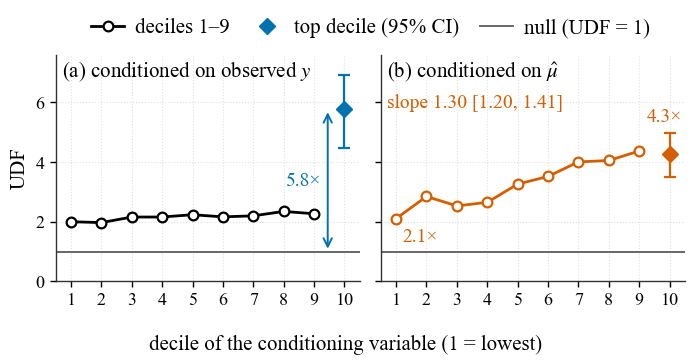

In [8]:
H1 = 9.0
fig, axs = plt.subplots(1, 2, figsize=(W, H1*CM), sharey=True)
fig.subplots_adjust(left=0.085, right=0.985, bottom=0.215, top=0.855, wspace=0.07)
cc = np.arange(5, 100, 10); YTOP = 7.6

def frame(ax):
    ax.axhline(1.0, ls="-", lw=1.4, color=CREF, zorder=2)
    ax.set_xlim(0, 100); ax.set_ylim(0, YTOP); ax.set_xticks(cc)
    ax.set_xticklabels([str(k + 1) for k in range(10)])         # decile number, 1 = lowest
    ax.set_yticks([0, 2, 4, 6])

for ax, prof, lo, hi, col, lab in ((axs[0], prof_y, lo_y, hi_y, CK, r"(a) conditioned on observed $y$"),
                                    (axs[1], prof_mu, lo_m, hi_m, CO, r"(b) conditioned on $\hat\mu$")):
    tc = CP if col == CK else CO                       # top-decile colour, as in the paper
    ax.plot(cc[:9], prof[:9], "-", color=col, lw=2.0, zorder=5)
    ax.plot(cc[:9], prof[:9], "o", ms=7, mfc="white", mec=col, mew=1.6, zorder=6)
    ax.errorbar(cc[9], prof[9], yerr=[[prof[9]-lo[9]], [hi[9]-prof[9]]], fmt="none",
                ecolor=tc, elinewidth=1.6, capsize=4, capthick=1.6, zorder=7)
    ax.plot(cc[9], prof[9], "D", ms=8.5, mfc=tc, mec=tc, zorder=8)
    frame(ax)
    ax.text(0.02, 0.98, lab, transform=ax.transAxes, ha="left", va="top", fontsize=FS_LAB)

axs[0].annotate("", xy=(cc[9]-5.5, prof_y[9]), xytext=(cc[9]-5.5, 1.0),
                arrowprops=dict(arrowstyle="<->", lw=1.4, color=CP), zorder=9)
axs[0].text(cc[9]-8, (prof_y[9]+1.0)/2, f"{prof_y[9]:.1f}×", fontsize=FS_ANN, color=CP, ha="right", va="center")
axs[1].text(cc[0]+2, prof_mu[0]-0.3, f"{prof_mu[0]:.1f}×", fontsize=FS_ANN, color=CO, ha="left", va="top")
axs[1].text(cc[9]+4, hi_m[9]+0.25, f"{prof_mu[9]:.1f}×", fontsize=FS_ANN, color=CO, ha="right", va="bottom")
axs[1].text(0.02, 0.83, f"slope {b_mu:.2f} [{ci_b[0]:.2f}, {ci_b[1]:.2f}]", transform=axs[1].transAxes,
            fontsize=FS_ANN, color=CO, ha="left", va="top")
axs[0].set_ylabel("UDF")
fig.supxlabel("decile of the conditioning variable (1 = lowest)", fontsize=FS_LAB, y=0.01)

handles = [Line2D([], [], color=CK, lw=2.0, marker="o", ms=7, mfc="white", mew=1.6, label="deciles 1–9"),
           Line2D([], [], color=CP, ls="none", marker="D", ms=8.5, label="top decile (95% CI)"),
           Line2D([], [], color=CREF, lw=1.4, label="null (UDF = 1)")]
fig.legend(handles=handles, loc="upper center", ncol=3, bbox_to_anchor=(0.535, 1.0),
           handlelength=1.6, columnspacing=1.0, handletextpad=0.5, fontsize=FS_LEG)
assert max(hi_y[9], hi_m[9], prof_y.max(), prof_mu.max()) <= YTOP
save(fig, "poster_fig1_conditionings", H1); plt.show()

## §5 — Poster Fig. 2: ranked right, sized wrong

Paper Fig. 2. Panel (a) holds the sparsification curves, with AUSE values in the legend. Panel (b) plots per-catchment AUSE against UDF. At 15 pt the legend does not fit inside panel (a), so it sits below both panels. The value in brackets on the filled-marker entry is the median UDF of the catchments that beat the pooled AUSE.

saved figures/poster/poster_fig2_ause.{pdf,png}  17.75 x 14.0 cm  (2795 x 2204 px)


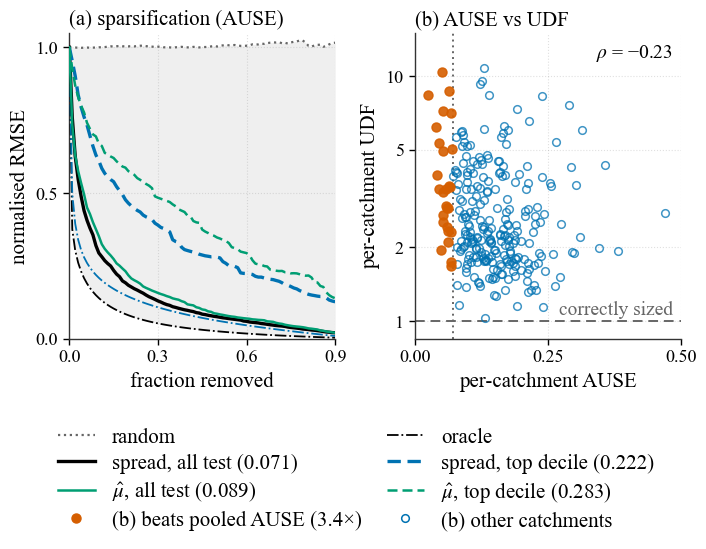

In [9]:
H2 = 14.0
fig, axs = plt.subplots(1, 2, figsize=(W, H2*CM))
fig.subplots_adjust(left=0.09, right=0.965, bottom=0.375, top=0.93, wspace=0.30)
_, cp_a, co_a, cr_a, fr = CURVES["all test"]; _, cp_t, co_t, _, _ = CURVES["top flow decile"]
AUa, AUt = CURVES["all test"][0], CURVES["top flow decile"][0]
AFa, AFt = CURVES_FLOW["all test"][0], CURVES_FLOW["top flow decile"][0]

a0 = axs[0]
a0.fill_between(fr, co_a, cr_a, color=CREF, alpha=0.10, lw=0, zorder=1)
a0.plot(fr, cr_a, ls=":", color=CREF, lw=1.6, zorder=3, label="random")
a0.plot(fr, co_a, ls="-.", color=CK, lw=1.3, zorder=3, label="oracle")
a0.plot(fr, co_t, ls="-.", color=CP, lw=1.3, zorder=3)
a0.plot(fr, cp_a, "-", color=CK, lw=2.4, zorder=4, label=f"spread, all test ({AUa:.3f})")
a0.plot(fr, cp_t, ls=(0, (4, 2)), color=CP, lw=2.4, zorder=4, label=f"spread, top decile ({AUt:.3f})")
a0.plot(fr, CURVES_FLOW["all test"][1], "-", color=CG, lw=1.8, zorder=5,
        label=r"$\hat\mu$, all test" + f" ({AFa:.3f})")
a0.plot(fr, CURVES_FLOW["top flow decile"][1], ls=(0, (4, 2)), color=CG, lw=1.8, zorder=5,
        label=r"$\hat\mu$, top decile" + f" ({AFt:.3f})")
a0.set_xlim(0, 0.9); a0.set_ylim(0, 1.05)
a0.set_xticks([0, 0.3, 0.6, 0.9]); a0.set_yticks([0, 0.5, 1.0])
a0.set_xlabel("fraction removed"); a0.set_ylabel("normalised RMSE")
a0.set_title("(a) sparsification (AUSE)", loc="left", fontsize=FS_LAB)

a1 = axs[1]
best = (_fig2b.ause <= AUa).values; pa, pr = _fig2b.ause.values, _fig2b.udf.values
a1.axhline(1.0, ls=(0, (5, 3)), lw=1.4, color=CREF, zorder=2)
a1.axvline(AUa, ls=(0, (1, 2)), lw=1.4, color=CREF, zorder=2)
a1.plot(pa[~best], pr[~best], "o", ms=5.5, mfc="none", mec=CP, mew=1.1, alpha=0.75, zorder=4)
a1.plot(pa[best], pr[best], "o", ms=6.5, mfc=CO, mec=CO, alpha=0.9, zorder=5)
a1.set_yscale("log"); a1.set_xlim(0, 0.50); a1.set_ylim(0.85, 15)
a1.set_xticks([0, 0.25, 0.5]); a1.set_yticks([1, 2, 5, 10]); a1.set_yticklabels(["1", "2", "5", "10"])
a1.minorticks_off()
a1.text(0.97, 0.97, f"$\\rho$ = {rho.statistic:+.2f}".replace("-", "−"), transform=a1.transAxes,
        fontsize=FS_ANN, ha="right", va="top")
a1.text(0.485, 1.03, "correctly sized", fontsize=FS_ANN, color=CREF, ha="right", va="bottom")
a1.set_xlabel("per-catchment AUSE"); a1.set_ylabel("per-catchment UDF")
a1.set_title("(b) AUSE vs UDF", loc="left", fontsize=FS_LAB)

h, l = a0.get_legend_handles_labels()
h += [Line2D([], [], ls="none", marker="o", ms=6.5, mfc=CO, mec=CO),
      Line2D([], [], ls="none", marker="o", ms=5.5, mfc="none", mec=CP, mew=1.1)]
l += [f"(b) beats pooled AUSE ({np.median(pr[best]):.1f}×)", "(b) other catchments"]
_ord = [0, 2, 4, 6, 1, 3, 5, 7]                # filled column-wise into two columns of four
fig.legend([h[i] for i in _ord], [l[i] for i in _ord], loc="lower center", ncol=2,
           bbox_to_anchor=(0.5, 0.0), handlelength=1.8, columnspacing=1.2, labelspacing=0.3,
           fontsize=FS_LEG)
save(fig, "poster_fig2_ause", H2); plt.show()

## §6 — Choosing the hydrograph catchment

For each catchment the event is its largest observed test-period day. The criteria, in the brief's priority order:

1. test-period NSE ≥ 0.7;
2. the event exceeds the catchment's 1980–2005 p99. Exceeding the 1980–2005 maximum ranks higher, and a peak in the November 2021 atmospheric-river floods ranks higher again;
3. the observed peak lies outside the ±2-spread band, meaning error/spread > 2 that day. Larger is clearer;
4. the hydrograph is visually clean. The proxy here is glacier cover < 5 %, which rules out a melt plateau.

Ranking applies 2 first (max > Nov 2021 > p99), then sorts by error/spread. No criterion had to be relaxed.

In [10]:
import geopandas as gpd
# HYDAT station names from the drainage-area station layer
NAMES = pd.concat([gpd.read_file(p, layer="Station", columns=["StationNum", "NameNom"], ignore_geometry=True)
                   for p in DRAINAGE_FILES]).drop_duplicates("StationNum").set_index("StationNum")["NameNom"]

ev = []
for j, sid in enumerate(stations):
    i = int(np.argmax(np.where(TEST[:, j], y[:, j], -np.inf)))       # largest test-period day
    lv = LEVELS.loc[sid]
    ev.append(dict(station_id=sid, name=NAMES.get(sid, "?").title(), event=dates[i].date(),
                   obs=float(y[i, j]), mu=float(mu[i, j]), spread=float(spread[i, j]),
                   err_over_spread=float(resid[i, j]/spread[i, j]),
                   level="max" if y[i, j] > lv["max"] else "p99" if y[i, j] > lv["p99"]
                         else "p90" if y[i, j] > lv["p90"] else "<p90",
                   x_train_max=float(y[i, j]/lv["max"]), glacier_pct=ST.loc[sid, "glacier_pct"]))
EV = pd.DataFrame(ev).set_index("station_id").join(PB[["nse", "udf", "ause"]])
EV["nov2021"] = pd.to_datetime(EV.event).between("2021-11-01", "2021-11-30")

ok = EV[(EV.nse >= 0.7) & EV.level.isin(["p99", "max"]) & (EV.err_over_spread > 2) & (EV.glacier_pct < 5)]
ok = ok.assign(_tier=(ok.level == "max")*2 + ok.nov2021*1).sort_values(["_tier", "err_over_spread"], ascending=False)
print(f"{(EV.nse >= 0.7).sum()} catchments with NSE >= 0.7; {len(ok)} pass all four criteria; "
      f"{int((ok.level == 'max').sum())} exceed their 1980-2005 maximum, "
      f"{int(((ok.level == 'max') & ok.nov2021).sum())} of them in November 2021")
TOP5 = ok.head(5)[["name", "nse", "udf", "ause", "event", "level", "x_train_max", "err_over_spread", "glacier_pct"]]
PICK = TOP5.index[0]
print(f"pick: {PICK} {TOP5.loc[PICK, 'name']}")
TOP5.round(2)

150 catchments with NSE >= 0.7; 109 pass all four criteria; 51 exceed their 1980-2005 maximum, 5 of them in November 2021
pick: 08NL024 Tulameen River At Princeton


,name,nse,udf,ause,event,level,x_train_max,err_over_spread,glacier_pct
station_id,,,,,,,,,
08NL024,Tulameen River At Princeton,0.83,1.81,0.13,2021-11-15,max,1.63,19.77,0.00
08LG048,Coldwater River Near Brookmere,0.71,2.57,0.14,2021-11-15,max,2.50,16.62,0.00
08NL038,Similkameen River Near Hedley,0.89,1.74,0.11,2021-11-15,max,1.48,12.27,0.01
08NL070,Similkameen River Above Goodfellow Creek,0.88,1.52,0.19,2021-11-15,max,1.24,11.49,0.04
08MH016,Chilliwack River At Outlet Of Chilliwack Lake,0.84,1.90,0.23,2021-11-16,max,1.14,4.54,2.32


## §7 — Poster map

Uses cartopy with Natural Earth for coastline, provinces, lakes and ocean. The 50 m files are not in the local cartopy cache, so this uses the cached 10 m files and never touches the network. Catchment polygons come from the drainage-area GeoPackages. Nested catchments overlap, so they are drawn largest first.

In [11]:
import cartopy.crs as ccrs, cartopy.feature as cfeature
from matplotlib.colors import LogNorm
import matplotlib.patheffects as pe

PROJ = ccrs.LambertConformal(central_longitude=-121, central_latitude=54, standard_parallels=(50, 58))
_where = "StationNum IN (" + ",".join(f"'{s}'" for s in stations) + ")"
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    POLY = pd.concat([gpd.read_file(p, layer="DrainageBasin_BassinDeDrainage", where=_where,
                                    columns=["StationNum"]) for p in DRAINAGE_FILES])
POLY = POLY.drop_duplicates("StationNum").to_crs(PROJ.proj4_init)
POLY["geometry"] = POLY.geometry.simplify(500)       # 500 m: invisible at this scale, much smaller PDF
POLY = POLY.assign(_a=POLY.area).sort_values("_a", ascending=False)
assert len(POLY) == NBAS, f"{len(POLY)} polygons for {NBAS} catchments"
ne = lambda cat, name: cfeature.NaturalEarthFeature(cat, name, "10m")
print(f"{len(POLY)} catchment polygons loaded")

269 catchment polygons loaded


saved figures/poster/poster_map.{pdf,png}  17.75 x 13.0 cm  (2795 x 2047 px)


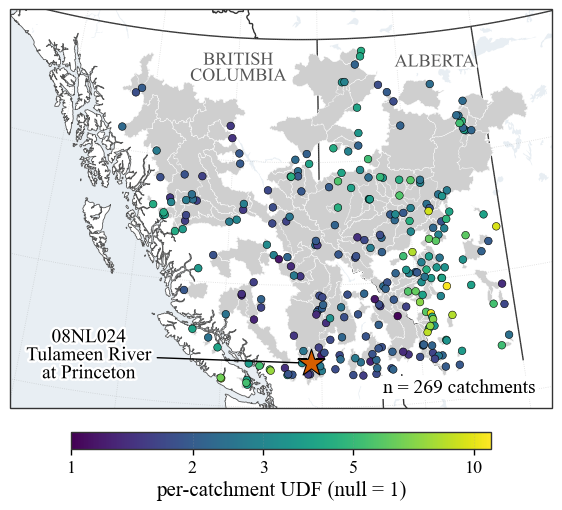

In [12]:
HM = 13.0
fig = plt.figure(figsize=(W, HM*CM))
ax = fig.add_axes([0.005, 0.215, 0.99, 0.78], projection=PROJ)
ax.set_extent([-135.0, -109.0, 47.3, 60.3], crs=ccrs.PlateCarree())
ax.add_feature(ne("physical", "ocean"), facecolor="#e8eef3", edgecolor="none", zorder=0)
ax.add_feature(ne("physical", "lakes"), facecolor="#e8eef3", edgecolor="none", zorder=1)
ax.add_feature(ne("physical", "coastline"), facecolor="none", edgecolor="#555555", lw=0.6, zorder=2)
ax.add_feature(ne("cultural", "admin_1_states_provinces_lines"), facecolor="none",
               edgecolor="#333333", lw=1.0, zorder=2)
ax.add_geometries(POLY.geometry, crs=PROJ, facecolor="#cfcfcf", edgecolor="white", lw=0.3, zorder=3)
gl = ax.gridlines(draw_labels=False, color="#999999", alpha=0.35, lw=0.6, ls=":",
                  xlocs=range(-135, -105, 5), ylocs=range(48, 62, 4))

# gauges coloured by per-catchment UDF on a log scale (null = 1)
pts = ST.loc[stations]
sc = ax.scatter(pts.longitude, pts.latitude, c=PB.loc[stations, "udf"], cmap="viridis",
                norm=LogNorm(1, 11), s=30, edgecolors="black", linewidths=0.4,
                transform=ccrs.PlateCarree(), zorder=5)
assert PB.udf.between(1, 11).all(), "a UDF falls outside the colour range"

# the hydrograph catchment
plon, plat = pts.loc[PICK, ["longitude", "latitude"]]
ax.scatter(plon, plat, marker="*", s=420, facecolor=CO, edgecolor="black", linewidths=0.8,
           transform=ccrs.PlateCarree(), zorder=7)
halo = [pe.withStroke(linewidth=3.5, foreground="white")]
# label sits in the open Pacific south-west of the gauge, joined by a leader line
_lab = NAMES[PICK].title().replace(" At ", "\nat ").replace(" Near ", "\nnear ")
ax.annotate(f"{PICK}\n{_lab}", xy=(plon, plat), xycoords=ccrs.PlateCarree()._as_mpl_transform(ax),
            xytext=(-131.6, 49.2), textcoords=ccrs.PlateCarree()._as_mpl_transform(ax),
            ha="center", va="center", fontsize=FS_ANN, linespacing=1.0, path_effects=halo, zorder=8,
            arrowprops=dict(arrowstyle="-", lw=1.0, color=CK, shrinkA=2, shrinkB=9))

for txt, lon, lat in (("BRITISH\nCOLUMBIA", -125.0, 59.0), ("ALBERTA", -112.6, 59.0)):
    ax.text(lon, lat, txt, transform=ccrs.PlateCarree(), fontsize=FS_TICK, color="#555555",
            ha="center", va="center", linespacing=1.0, path_effects=halo, zorder=6)
ax.text(0.97, 0.03, f"n = {NBAS} catchments", transform=ax.transAxes, ha="right", va="bottom",
        fontsize=FS_ANN, bbox=dict(fc="white", ec="none", pad=2), zorder=9)

cax = fig.add_axes([0.20, 0.135, 0.60, 0.033])
cb = fig.colorbar(sc, cax=cax, orientation="horizontal")
cb.set_ticks([1, 2, 3, 5, 10]); cb.set_ticklabels(["1", "2", "3", "5", "10"]); cb.minorticks_off()
cb.ax.tick_params(labelsize=FS_TICK, width=1.0, length=4)
cb.set_label("per-catchment UDF (null = 1)", fontsize=FS_LAB, labelpad=3)
save(fig, "poster_map", HM); plt.show()

## §8 — Poster hydrograph

The chosen catchment over a six-month test-period window around its event. The band is $\hat\mu \pm 2$ corrected spread. The annotation gives that day's residual as a multiple of the corrected spread.

saved figures/poster/poster_hydrograph.{pdf,png}  17.75 x 8.0 cm  (2795 x 1259 px)


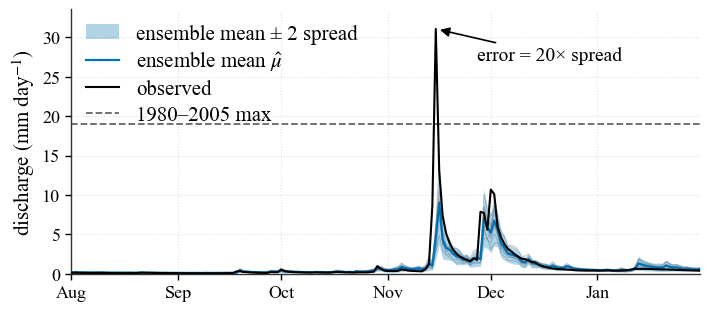

08NL024 Tulameen River At Princeton  event 2021-11-15: observed 31.08, mu-hat 4.61, corrected spread 1.339 mm/day; band upper edge 7.29; error/spread 19.77; 1.63x the 1980-2005 max (19.07 mm/day)


In [13]:
HH = 8.0
j = stations.index(PICK); e = EV.loc[PICK]
t_ev = pd.Timestamp(e.event)
win = (dates >= "2021-08-01") & (dates <= "2022-01-31")
assert t_ev in dates[win] and test[win].all(), "window must sit inside the test period"
d, yo, mh, sp, mem = dates[win], y[win, j], mu[win, j], spread[win, j], members[:, win, j]

fig, ax = plt.subplots(figsize=(W, HH*CM))
fig.subplots_adjust(left=0.085, right=0.985, bottom=0.135, top=0.975)
for k in range(M):                                                    # z-order 1: members
    ax.plot(d, mem[k], color="#9a9a9a", lw=0.6, alpha=0.6, zorder=1)
ax.fill_between(d, mh - 2*sp, mh + 2*sp, color=CP, alpha=0.3, lw=0, zorder=2,
                label="ensemble mean ± 2 spread")
ax.plot(d, mh, color=CP, lw=1.6, zorder=3, label=r"ensemble mean $\hat\mu$")
ax.plot(d, yo, color=CK, lw=1.5, zorder=4, label="observed")
ax.axhline(LEVELS.loc[PICK, "max"], color=CREF, ls="--", lw=1.3, zorder=2, label="1980–2005 max")

ax.annotate(f"error = {e.err_over_spread:.0f}× spread", xy=(t_ev, e.obs),
            xytext=(t_ev + pd.Timedelta(days=12), e.obs*0.93), fontsize=FS_ANN, ha="left", va="top",
            arrowprops=dict(arrowstyle="-|>", lw=1.2, color=CK, shrinkB=3), zorder=6)
ax.set_xlim(d[0], d[-1]); ax.set_ylim(0, e.obs*1.08)
ax.xaxis.set_major_locator(mpl.dates.MonthLocator())
ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%b"))
ax.set_ylabel(r"discharge (mm day$^{-1}$)")
ax.legend(loc="upper left", frameon=False, fontsize=FS_LEG, handlelength=1.6, labelspacing=0.3)
save(fig, "poster_hydrograph", HH); plt.show()

# outer edge of the band on the event day, for the report
print(f"{PICK} {NAMES[PICK].title()}  event {t_ev.date()}: observed {e.obs:.2f}, mu-hat {e.mu:.2f}, "
      f"corrected spread {e.spread:.3f} mm/day; band upper edge {e.mu + 2*e.spread:.2f}; "
      f"error/spread {e.err_over_spread:.2f}; {e.x_train_max:.2f}x the 1980-2005 max "
      f"({LEVELS.loc[PICK, 'max']:.2f} mm/day)")

## §9 — Report values

All values that go into the report below, printed from the arrays so that a rerun shows they still hold.

In [14]:
_r = EV.loc[PICK]
print(f"catchment      {PICK}  {NAMES[PICK].title()}")
print(f"area           {ST.loc[PICK, 'basin_area_km2']:.0f} km2;  glacier cover {ST.loc[PICK, 'glacier_pct']:.2f} %")
print(f"test NSE       {_r.nse:.3f}")
print(f"UDF            {_r.udf:.2f}   (all-catchment median {PB.udf.median():.2f})")
print(f"AUSE           {_r.ause:.3f}  (pooled all-test {CURVES['all test'][0]:.3f})")
print(f"event          {_r.event}: {_r.obs:.2f} mm/day observed vs mu-hat {_r.mu:.2f} +/- 2 x {_r.spread:.3f}")
print(f"exceedance     above 1980-2005 {_r.level}; {_r.x_train_max:.2f}x the training max "
      f"{LEVELS.loc[PICK, 'max']:.2f} mm/day (p99 {LEVELS.loc[PICK, 'p99']:.2f})")
print(f"annotation     error/spread = {_r.err_over_spread:.2f} -> 'error = {_r.err_over_spread:.0f}x spread'")
print(f"map            UDF range {PB.udf.min():.2f}-{PB.udf.max():.2f}, all {int((PB.udf > 1).sum())}/{NBAS} > 1")

catchment      08NL024  Tulameen River At Princeton
area           1776 km2;  glacier cover 0.00 %
test NSE       0.830
UDF            1.81   (all-catchment median 2.33)
AUSE           0.128  (pooled all-test 0.071)
event          2021-11-15: 31.08 mm/day observed vs mu-hat 4.61 +/- 2 x 1.339
exceedance     above 1980-2005 max; 1.63x the training max 19.07 mm/day (p99 7.25)
annotation     error/spread = 19.77 -> 'error = 20x spread'
map            UDF range 1.03-10.78, all 269/269 > 1


## Report

**Chosen catchment: 08NL024, Tulameen River at Princeton, BC.** Area 1,776 km², no glacier cover. Test-period NSE 0.830. Per-catchment UDF 1.81, below the all-catchment median of 2.33. Per-catchment AUSE 0.128, against a pooled all-test value of 0.071.

**Why this one.** It meets all four criteria and needed none relaxed: 150 catchments have NSE ≥ 0.7 and 109 pass all four. Among the five that exceeded their 1980–2005 maximum during the November 2021 atmospheric-river floods, it has the largest error/spread. Runners-up, all from 15–16 Nov 2021: 08LG048 (NSE 0.71, error 17× spread), 08NL038 (12×), 08NL070 (11×), 08MH016 (5×). 08LG048 has the larger exceedance (2.50× its maximum), but its NSE only just clears the 0.7 bar.

**Event.** 15 November 2021. Observed 31.08 mm/day, which is 1.63× the 1980–2005 maximum of 19.07 mm/day; the 1980–2005 p99 is 7.25 mm/day. The ensemble mean was 4.61 mm/day with a corrected spread of 1.339 mm/day, so the band's upper edge was 7.29 mm/day.

**Annotation.** Residual / corrected spread = (31.08 − 4.61) / 1.339 = 19.77, printed as "error = 20× spread".

**Inputs.** The per-catchment UDF/AUSE table and the style helper were not on disk; both were recomputed from notebook 02's code, and the paper's ρ = −0.230 reproduces. The catchment polygons come from the drainage-area GeoPackages that `src/config.py` points to. Natural Earth 10 m was used because 50 m is not in the offline cartopy cache.

**Captions.**

- *Map:* "The 269 unregulated catchments in British Columbia and Alberta, each gauge coloured by its test-period under-dispersion factor (UDF; 1 = spread correctly sized). Every catchment is above 1 (range 1.03–10.8), and the star marks the hydrograph catchment."
- *Hydrograph:* "Tulameen River at Princeton (08NL024) during the November 2021 atmospheric-river flood. The observed peak was 1.6× the largest flow in the 1980–2005 training record and fell 20 ensemble spreads above the ensemble mean, far outside the ±2-spread band."
- *Fig. 1:* "Ensemble spread understates error in every flow decile. Conditioned on the model's own prediction, the shortfall grows from 2.1× to 4.3× (log–log slope 1.30), so no constant rescaling can fix it."
- *Fig. 2:* "The spread ranks errors well (AUSE 0.071) but sizes them badly. Across catchments, ranking quality and sizing are negatively correlated (ρ = −0.23), and even the best-ranking catchments under-disperse by a median 3.4×."
